# Q2F | Final Predictions

> *Make predictions of the labels on the test data, using the trained model with chosen (best) hyperparameters. Summarize performance using the RMSE.*

The trained models are the two that parts D and E selected, fit on the training data and saved: a linear regression and a polynomial regression.

---

#### IMPORTANT

This dataset has no `train` / `test` split of its own, so the same chronological split as Q2B to Q2E is made at the top of this notebook: the earliest 584 days are `train` and the latest 147 days are `test`. This is the only notebook that scores a model on the `test` days. Both models were selected, fit and saved before it, on the training rows only, and nothing is refit or tuned here. The final model, the tables, the charts and the test for whether the cross validated estimate held were fixed in Method before any test score was computed, so no choice below is influenced by the test data (`data snooping`).

# Answer Summary

**Setup:** the two pipelines Q2D and Q2E saved are loaded as they are and predict the 147 test days (2012-08-07 to 2012-12-31) from the 11 stored attributes. Nothing is refit or tuned. The metric is rmse, in `Rentals` units. The final model is the polynomial regression, chosen from cross validation before any test day was predicted.

**Cross validated estimate, training rmse and test rmse**

| Model | cv rmse (lowest to highest fold) | train rmse | test rmse, first 46 days | test rmse, all 147 days (95% interval) |
|---|---|---|---|---|
| Linear: Lasso SGD, `alpha=0.001`, `eta0=0.0001` | 792.708 (704.347 to 891.022) | 613.372 | 1135.930 | 1112.991 (847.493 to 1382.729) |
| Polynomial (final): degree 2, Lasso SGD, `alpha=0.001`, `eta0=0.001` | 767.440 (652.994 to 887.655) | 569.145 | 789.754 | 978.247 (767.292 to 1184.364) |

Each fold validated on the 46 days after its training rows, so the first 46 test days are what the estimate is for. The interval comes from a bootstrap over the test days in blocks of 7. It leaves out the noise from the training rows, so the true noise is at least this large.

- **Predictions:** each model predicts all 147 test days. The final model's predictions run from 1673.0 to 7578.7, a narrower range than the actual values (22.0 to 8714.0).
- **RMSE:** the final model's test rmse is 978.247, with an mae of 722.659 and an r2 of 0.728. The linear model's is 1112.991. The polynomial model is lower by 134.744, and the 95% interval of that difference (-327.816 to -18.974) does not include 0. Most of the gap is one day: without 2012-08-17 the two models score 973.663 and 1020.113 (a check added after the test scores were seen).
- **The cross validated estimate held for the final model on the days it was made for.** On the first 46 test days its rmse is 789.754, inside its fold range. The linear model's is 1135.930, outside its range, because of that one day, where `FeelsLike` (0.242) is far from `Temp` (0.723): without it the linear model scores 805.420, inside its range. Further ahead neither estimate holds: on the later 101 days rmse is 1052.971 and 1102.385.
- **Where the predictions miss:** on days with few rentals, which both models predict far too high (an rmse of 2117.411 for the final model on the 9 days below 2000). Month 10 is the worst month (1251.175), and the final model is too low on average in months 8 to 10 and too high in months 11 and 12.

---

# Imports

In [1]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone

from Q2.consts import *

from utils import (
	read_csv_to_df,
	PLOTTING,
	SCORING,
	PIPELINES,
)

from Q2.utils import (
	chronological_split,
	make_time_folds,
	Q2_PLOTTING,
)

# Fetch Data

In [2]:
df = read_csv_to_df(path=DATA_PATH, parse_dates=["dteday"])
df = df.rename(columns=SHORT_NAMES)

# Train / Test Split

In [3]:
train_df, test_df = chronological_split(df=df, date_col="Date", test_size=TEST_SIZE)

pd.DataFrame({
	"rows": [len(train_df), len(test_df)],
	"% of rows": [round(len(train_df) / len(df) * 100, 2), round(len(test_df) / len(df) * 100, 2)],
	"first date": [f"{train_df['Date'].min():%Y-%m-%d}", f"{test_df['Date'].min():%Y-%m-%d}"],
	"last date": [f"{train_df['Date'].max():%Y-%m-%d}", f"{test_df['Date'].max():%Y-%m-%d}"],
}, index=["train", "test"])

,rows,% of rows,first date,last date
train,584,79.89,2011-01-01,2012-08-06
test,147,20.11,2012-08-07,2012-12-31


## Rows by Year and Month

The days each side of the split holds, for the months the test days fall in. `Year` is 0 for the first year and 1 for the second.

In [4]:
assert (test_df["Year"] == 1).all()

rows_by_month = pd.DataFrame({
	"train, Year 0": train_df[train_df["Year"] == 0].groupby("Month").size(),
	"train, Year 1": train_df[train_df["Year"] == 1].groupby("Month").size(),
	"test, Year 1": test_df.groupby("Month").size(),
}).reindex(sorted(test_df["Month"].unique())).fillna(0).astype(int)
rows_by_month

,"train, Year 0","train, Year 1","test, Year 1"
Month,,,
8,31,6,25
9,30,0,30
10,31,0,31
11,30,0,30
12,31,0,31


## Attributes

In [5]:
CONTINUOUS = ["Temp", "FeelsLike", "Humidity", "Wind"]
BINARY = ["Year", "IsHoliday", "IsWorkday"]
MULTI_LEVEL = ["Season", "Month", "Weekday", "Weather"]

# the same 11 attributes as Q2D and Q2E, in the order both pipelines were fit on. ID, Date, Casual and Registered
# are left out, as concluded in Q2B
ATTRIBUTES = CONTINUOUS + BINARY + MULTI_LEVEL

X = train_df[ATTRIBUTES]
y = train_df[TARGET]

X_test = test_df[ATTRIBUTES]
y_test = test_df[TARGET]

print(f"attributes: {len(ATTRIBUTES)} | missing values in train: {int(X.isna().sum().sum())} | in test: {int(X_test.isna().sum().sum())}")

attributes: 11 | missing values in train: 0 | in test: 0


# Method

Q2D and Q2E each selected one model with cross validation, fit it once on the 584 training rows and saved it as one `Pipeline`. Both are loaded here as they were saved. Each takes the 11 attributes as they are stored and builds its own feature columns, so this notebook does no preprocessing.

- **Nothing is refit or tuned.** The test days are used once, to score the two saved fits. No hyperparameter, feature or model choice changes after a test score is seen.
- **Check on the files:** the hyperparameters are read back from the loaded pipelines, and each fit's epochs and training rmse are compared with the values Q2D and Q2E printed (`REPORTED`).
- **Cross validated estimate:** a clone of each pipeline (the same steps and hyperparameters, none of the fitted values) is scored on the 4 time-ordered folds of Q2D and Q2E. Each fold trains on every day before its validation block and validates on the next 46 days. The clones are fit on training folds only, and the saved fits are not changed. A fold's rmse is a score on days its model did not train on, so the mean over the folds is the estimate of the test rmse.
- **The final model is the polynomial regression,** Q2E's. Its cross validated rmse is lower than the linear model's by more than 1 SE of the per-fold differences, the **candidate** verdict of Q2D and Q2E, and Cross Validated Estimate checks that again before a test day is predicted. With 4 folds that SE is a rough estimate. The linear model is scored next to it as the comparison. The choice is never made from the test scores.
- **Metric:** rmse, in `Rentals` units, the metric both models were selected with. mae and r2 are reported next to it.
- **The estimate holds** when a model's rmse on the first 46 test days lies between its lowest and its highest fold rmse. Those 46 days are what a fold measures: the days right after the training rows. The later 101 test days are further ahead than any fold reached, so their rmse, and the rmse of all 147 days, are reported against the same range as a separate question. Four fold scores make a rough range.
- **What the test days are:** months 8 to 12 of the second year. The training rows hold those months from the first year, and only the first 6 days of month 8 from the second (the table in Rows by Year and Month).
- **Noise on a test score:** the test days are resampled with replacement 10,000 times (a bootstrap, seeded with 42) and each model is scored on every resample. Days are drawn in blocks of 7 consecutive days, so a miss that carries over from one day to the next stays inside a block. `SE` is the sd of those scores, and `2.5%` and `97.5%` are the ends of the interval that holds 95% of them. Both models are scored on the same resamples, so the difference between them has its own SE and interval.
  - **What it covers:** how much a score depends on which weeks of the test period it holds.
  - **What it leaves out:** the two fits are fixed, so the noise from the training rows is not in it. It also treats days more than a week apart as independent of each other. The true noise is at least this large.
  - **Linear against polynomial:** the test days separate the two models only if the interval of the difference does not include 0.
- **Where the predictions miss:** the error is predicted minus actual, so a positive mean error is a model that predicts too high. The test days are looked at by date, by month, as the 5 largest misses of the final model, and in `Rentals` bands with edges at 2000, 4000 and 6000, once by actual value and once by the value the final model predicted. A model that is right on average still looks too high on the days with the lowest actual values and too low on the highest, because those days are picked for their actual value. Grouping by predicted value does not have that effect: there a mean error away from 0 is a level the model gets wrong.
- **Seed:** the folds are not shuffled, so they need no seed. Every `random_state` in a clone is set to 42, and the bootstrap is seeded with 42, so a rerun gives the same numbers.

Anything added to this notebook after the test scores were seen is labeled as added afterwards.

# Load the Models

The two saved pipelines, first as they were saved, then scored again on the folds they were selected with. This section uses training rows only.

## The Saved Fits

Each pipeline's steps and hyperparameters, read back from the loaded object. Then its epochs and training rmse, next to the values Q2D and Q2E printed.

In [6]:
LINEAR, POLYNOMIAL = "Linear", "Polynomial"

MODELS = {
	LINEAR: joblib.load(MODEL_OUTPUT_DIR / "linear_regression.joblib"),
	POLYNOMIAL: joblib.load(MODEL_OUTPUT_DIR / "polynomial_regression.joblib"),
}

# what Q2D and Q2E printed for these two fits and for their settings on the folds
REPORTED = {
	LINEAR: {"epochs run": 219_994, "train rmse": 613.372, "cv rmse": 792.708},
	POLYNOMIAL: {"epochs run": 1_753, "train rmse": 569.145, "cv rmse": 767.440},
}

described = pd.DataFrame({name: PIPELINES.describe_pipeline(model) for name, model in MODELS.items()}).T
display(described)

train_scores = pd.DataFrame({name: SCORING.prediction_scores(y, model.predict(X)) for name, model in MODELS.items()}).T

saved_fits = pd.DataFrame({
	"epochs run, reported": {name: REPORTED[name]["epochs run"] for name in MODELS},
	"epochs run": described["epochs run"],
	"train rmse, reported": {name: REPORTED[name]["train rmse"] for name in MODELS},
	"train rmse": train_scores["rmse"].round(3),
})
display(saved_fits)

# the files are the fits Q2D and Q2E describe
assert (saved_fits["epochs run"] == saved_fits["epochs run, reported"]).all()
assert (saved_fits["train rmse"] == saved_fits["train rmse, reported"]).all()

,steps,degree,penalty,alpha,eta0,tol,columns,epochs run
Linear,features > scale > model,1,l1,0.001,0.0001,0.001,10,219994
Polynomial,features > scale > model,2,l1,0.001,0.001,0.001,20,1753


,"epochs run, reported",epochs run,"train rmse, reported",train rmse
Linear,219994,219994,613.372,613.372
Polynomial,1753,1753,569.145,569.145


## Cross Validated Estimate

A clone of each pipeline scored on the 4 folds, with the linear model as the baseline. The second table has each fold's rmse, and the third has each estimate next to the one Q2D or Q2E reported, with its lowest and highest fold.

In [7]:
FOLDS = make_time_folds(train_df, date_col="Date", n_splits=CV_SPLITS, validation_size=CV_TEST_SIZE)

# a clone keeps a pipeline's steps and hyperparameters and none of its fitted values. Each clone is fit on the
# training rows of each fold, so the two saved fits are not changed
RESULTS = {
	name: PIPELINES.evaluate_pipeline(clone(model), X=X, y=y, folds=FOLDS, return_train_score=True)
	for name, model in MODELS.items()
}

cv_table = SCORING.results_df(RESULTS, baseline=LINEAR)
display(cv_table)

fold_rmse = pd.DataFrame({name: scores["rmse"] for name, scores in RESULTS.items()}, index=pd.RangeIndex(1, len(FOLDS) + 1, name="fold"))
fold_dates = pd.DataFrame({
	"train rows": [len(train_labels) for train_labels, _ in FOLDS.folds],
	"validation rows": [len(validation_labels) for _, validation_labels in FOLDS.folds],
	"validation first date": [f"{train_df.loc[labels, 'Date'].min():%Y-%m-%d}" for _, labels in FOLDS.folds],
	"validation last date": [f"{train_df.loc[labels, 'Date'].max():%Y-%m-%d}" for _, labels in FOLDS.folds],
}, index=fold_rmse.index)
display(fold_dates.join(fold_rmse.round(3)))

estimate = pd.DataFrame({
	"cv rmse, reported": {name: REPORTED[name]["cv rmse"] for name in MODELS},
	"cv rmse": fold_rmse.mean().round(3),
	"lowest fold": fold_rmse.min().round(3),
	"highest fold": fold_rmse.max().round(3),
})
display(estimate)

assert (estimate["cv rmse"] == estimate["cv rmse, reported"]).all()

# the final model is fixed here, from cross validation, before any test day is predicted
FINAL = POLYNOMIAL
assert cv_table.loc[FINAL, "verdict"] == "candidate"

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs Linear,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
Polynomial,767.440,97.661,522.146,600.826,91.041,0.500,0.129,-25.268,11.763,-2.148,0.06,candidate,4
Linear,792.708,78.107,570.165,602.409,71.633,0.461,0.160,0.000,NaN,NaN,NaN,baseline,4


,train rows,validation rows,validation first date,validation last date,Linear,Polynomial
fold,,,,,,
1,400,46,2012-02-05,2012-03-21,767.990,741.678
2,446,46,2012-03-22,2012-05-06,891.022,887.655
3,492,46,2012-05-07,2012-06-21,807.473,787.432
4,538,46,2012-06-22,2012-08-06,704.347,652.994


,"cv rmse, reported",cv rmse,lowest fold,highest fold
Linear,792.708,792.708,704.347,891.022
Polynomial,767.440,767.440,652.994,887.655


## Results

- **The files are the models Q2D and Q2E describe.** Both reload with the epochs and training rmse those notebooks printed: 219,994 epochs and 613.372 for the linear model, 1,753 epochs and 569.145 for the polynomial one.
- **The chosen hyperparameters, read from the pipelines:** both are Lasso (`l1`) at `alpha=0.001`. The linear model has 10 columns and `eta0=0.0001`. The polynomial model is degree 2 with 20 columns and `eta0=0.001`.
- **Rescoring on the 4 folds reproduces both estimates:** 792.708 for the linear model and 767.440 for the polynomial one.
- **The polynomial model is the final model.** Its cross validated rmse is lower by 25.268 with an SE of 11.763, a **candidate** on 4 folds and not more (p 0.06). It is the lower of the two on every fold, narrowly on fold 2 (887.655 against 891.022). That is settled before any test day is predicted.

**Carry forward**

- **What each test rmse is read against:** 792.708 for the linear model, with folds from 704.347 to 891.022, and 767.440 for the polynomial model, with folds from 652.994 to 887.655.

# Predictions

Each saved pipeline predicts `Rentals` for every test day from the 11 stored attributes. The first 10 days are shown next to the actual values, then the mean, sd, lowest and highest value of each column.

In [8]:
predictions = pd.DataFrame({name: model.predict(X_test) for name, model in MODELS.items()}, index=X_test.index)
assert predictions.notna().all().all()

print(f"test days: {len(X_test)} | predictions per model: {len(predictions)}")

with_actual = predictions.assign(actual=y_test)[["actual", *MODELS]]
display(with_actual.assign(Date=test_df["Date"].dt.strftime("%Y-%m-%d")).set_index("Date").head(10).round(1))
display(with_actual.agg(["mean", "std", "min", "max"]).round(1))

test days: 147 | predictions per model: 147


,actual,Linear,Polynomial
Date,,,
2012-08-07,7273,5998.3,6129.1
2012-08-08,7534,6013.7,6138.1
2012-08-09,7286,6530.4,6524.8
2012-08-10,5786,5956.4,6056.7
2012-08-11,6299,6228.9,6333.5
2012-08-12,6544,6943.9,7025.2
2012-08-13,6883,6794.4,6867.9
2012-08-14,6784,6496.6,6489.5
2012-08-15,7347,6792.3,6902.2


,actual,Linear,Polynomial
mean,5897.8,5707.5,5758.7
std,1881.0,1258.1,1201.2
min,22.0,1258.6,1673.0
max,8714.0,7316.7,7578.7


## Results

- **Every test day has a prediction from each model:** 147 days and 147 predictions per model, made from the stored attributes by the pipelines as they were saved.
- **The predictions cover a narrower range than the actual values.** The actual values run from 22.0 to 8714.0 with an sd of 1881.0. The linear model's predictions run from 1258.6 to 7316.7 (sd 1258.1) and the polynomial model's from 1673.0 to 7578.7 (sd 1201.2). Neither model comes near the lowest actual value.
- **Both models are low on average:** the mean prediction is 5707.5 and 5758.7, against a mean actual value of 5897.8.

# Test Scores

Each model's scores on all the test days, next to its cross validated estimate and the training rmse of its saved fit.

In [9]:
test_scores = pd.DataFrame({name: SCORING.prediction_scores(y_test, predictions[name]) for name in MODELS}).T

scores = pd.DataFrame({
	"cv rmse": estimate["cv rmse"],
	"train rmse": train_scores["rmse"],
	"test rmse": test_scores["rmse"],
	"test mae": test_scores["mae"],
	"test r2": test_scores["r2"],
}).round(3)
display(scores)

,cv rmse,train rmse,test rmse,test mae,test r2
Linear,792.708,613.372,1112.991,791.864,0.648
Polynomial,767.440,569.145,978.247,722.659,0.728


## Against the Folds

The test days split at the distance the folds measured: the first 46 days, and the days after them. The first table has the rows, mean error and rmse of each part, and the second sets each rmse against the range of the fold scores.

In [10]:
# each fold validated on the CV_TEST_SIZE days right after its training rows. The first CV_TEST_SIZE test days are
# the same distance from the saved fits' training rows, and the later test days are further than any fold reached
FIRST, LATER, ALL = f"first {CV_TEST_SIZE} test days", f"later {len(X_test) - CV_TEST_SIZE} test days", f"all {len(X_test)} test days"
horizon = pd.Series(np.where(np.arange(len(X_test)) < CV_TEST_SIZE, FIRST, LATER), index=X_test.index, name="test days")

by_horizon = SCORING.error_by_group(y_test, predictions, by=horizon)
display(by_horizon.round(3))

against_folds = pd.DataFrame({
	"lowest fold": estimate["lowest fold"],
	"highest fold": estimate["highest fold"],
	FIRST: by_horizon.loc[FIRST, "rmse"],
	LATER: by_horizon.loc[LATER, "rmse"],
	ALL: test_scores["rmse"],
}).round(3)
for column in [FIRST, LATER, ALL]:
	against_folds[f"{column}, inside the fold range"] = against_folds[column].between(against_folds["lowest fold"], against_folds["highest fold"])
display(against_folds.T)

rows mean error                 rmse           
                             Linear Polynomial    Linear Polynomial
test days                                                          
first 46 test days    46   -536.431   -427.551  1135.930    789.754
later 101 test days  101    -32.634     -7.664  1102.385   1052.971

,Linear,Polynomial
lowest fold,704.347,652.994
highest fold,891.022,887.655
first 46 test days,1135.93,789.754
later 101 test days,1102.385,1052.971
all 147 test days,1112.991,978.247
"first 46 test days, inside the fold range",False,True
"later 101 test days, inside the fold range",False,False
"all 147 test days, inside the fold range",False,False


## Noise

The bootstrap from Method, in blocks of 7 days: the SE and the 95% interval of each test rmse, and of the difference between the two models.

In [11]:
N_RESAMPLES = 10_000
BLOCK_SIZE = 7
DIFFERENCE = f"{POLYNOMIAL} minus {LINEAR}"

resampled = SCORING.bootstrap_rmse(y_test, predictions, n_resamples=N_RESAMPLES, block_size=BLOCK_SIZE, seed=42)
resampled[DIFFERENCE] = resampled[POLYNOMIAL] - resampled[LINEAR]

noise = pd.DataFrame({
	"test rmse": test_scores["rmse"],
	"SE": resampled.std(ddof=1),
	"2.5%": resampled.quantile(0.025),
	"97.5%": resampled.quantile(0.975),
})
noise.loc[DIFFERENCE, "test rmse"] = test_scores.loc[POLYNOMIAL, "rmse"] - test_scores.loc[LINEAR, "rmse"]
display(noise.round(3))

,test rmse,SE,2.5%,97.5%
Linear,1112.991,136.068,847.493,1382.729
Polynomial,978.247,105.658,767.292,1184.364
Polynomial minus Linear,-134.744,83.677,-327.816,-18.974


## Results

- **The final model's test rmse is 978.247,** with an mae of 722.659 and an r2 of 0.728. The linear model scores 1112.991, 791.864 and 0.648. Both are far above their training rmse (569.145 and 613.372).
- **The estimate held for the polynomial model and not for the linear one.** On the first 46 test days the polynomial model's rmse is 789.754, inside its fold range (652.994 to 887.655). The linear model's is 1135.930, above its highest fold (891.022).
- **Further ahead than the folds reached, both models miss by more than any fold showed.** On the later 101 days rmse is 1052.971 and 1102.385, and over all 147 days neither model is inside its fold range. The cross validated estimates (767.440 and 792.708) are for the next 46 days, and they understate the error over the whole 147 days. The later days are not missed by a level: their mean error is -7.664 and -32.634, against -427.551 and -536.431 on the first 46 days.
- **The polynomial model is also the better one on the test days, with a wide margin of noise.** Its test rmse is lower by 134.744 with an SE of 83.677, and the 95% interval of the difference (-327.816 to -18.974) does not include 0. The true noise is at least this large, so the test days support the cross validated ranking (a difference of -25.268 there) without settling it on their own. Most of the gap comes from one day (The Linear Model's Largest Misses).

**Carry forward**

- **Why the linear model misses on the first 46 test days,** which Where the Predictions Miss looks at.

# Where the Predictions Miss

Where the test errors are large: by date, by month and on single days, then by the size of the value.

## By Date

The actual `Rentals` and each model's prediction for every test day, with predicted minus actual below.

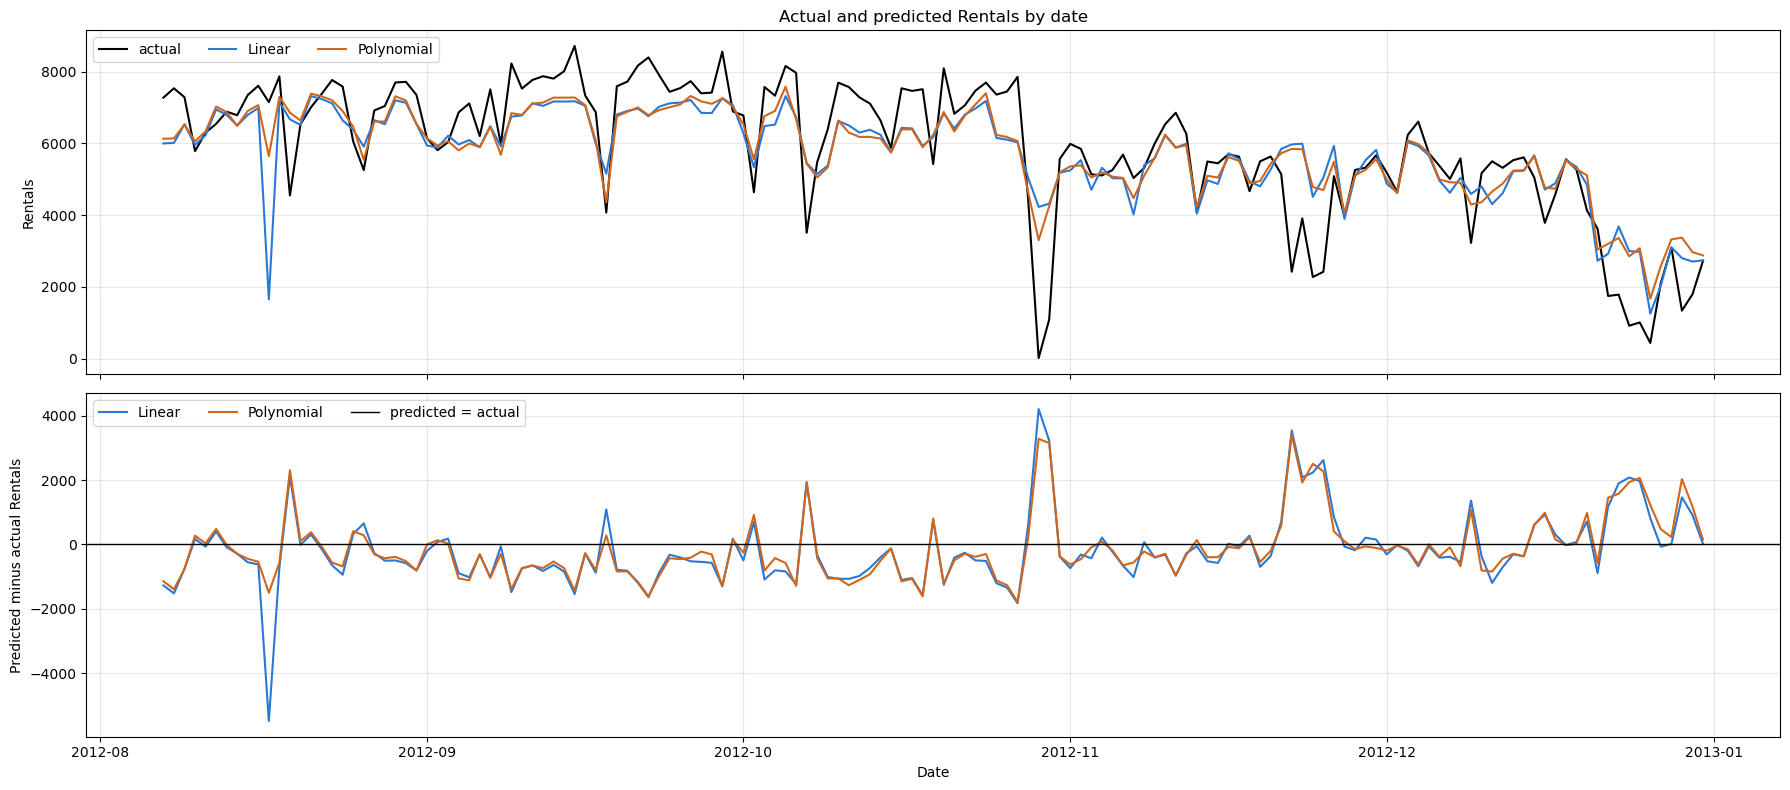

In [12]:
Q2_PLOTTING.predictions_by_date(dates=test_df["Date"], actual=y_test, predictions=predictions);

## By Month

Rows, mean error and rmse in each month of the test days. Month 8 holds only the days from the 7th.

In [13]:
display(SCORING.error_by_group(y_test, predictions, by=test_df["Month"]).round(3))

rows mean error                 rmse           
               Linear Polynomial    Linear Polynomial
Month                                                
8       25   -472.463   -246.535  1329.330    779.162
9       30   -628.919   -636.731   846.885    806.399
10      31   -328.669   -342.717  1350.177   1251.175
11      30    169.814    160.766  1081.181   1014.644
12      31    251.665    342.745   894.801    925.881

## Largest Misses

The 5 test days the final model misses by the most, with their stored weather attributes and both predictions.

In [14]:
error = predictions.sub(y_test, axis=0)
largest = error[FINAL].abs().nlargest(5).index

display(
	test_df.loc[largest, ["Date", "Weekday", "Weather", "Temp", "Humidity", "Wind"]]
	.assign(Date=lambda rows: rows["Date"].dt.strftime("%Y-%m-%d"))
	.assign(actual=y_test, **{f"{name}, predicted": predictions[name] for name in MODELS}, **{f"{FINAL}, error": error[FINAL]})
	.set_index("Date")
	.round(3)
)

,Weekday,Weather,Temp,Humidity,Wind,actual,"Linear, predicted","Polynomial, predicted","Polynomial, error"
Date,,,,,,,,,
2012-11-22,4,1,0.340,0.580,0.053,2425,5970.342,5845.786,3420.786
2012-10-29,1,3,0.440,0.880,0.358,22,4229.552,3305.191,3283.191
2012-10-30,2,2,0.318,0.825,0.213,1096,4320.811,4246.998,3150.998
2012-11-24,6,1,0.278,0.405,0.377,2277,4510.788,4783.997,2506.997
2012-08-19,0,2,0.636,0.712,0.086,4549,6668.802,6855.804,2306.804


## The Linear Model's Largest Misses (Added Afterwards)

**Added after the test scores were seen.** Method lists the largest misses of the final model only. The linear model's first 46 test days fell outside its fold range, so the same table is shown for it, with `Temp` next to `FeelsLike`. Below it: how far apart those two attributes are on the training days, then both models scored again without the day of the linear model's largest miss. No model changes because of it.

In [15]:
largest_linear = error[LINEAR].abs().nlargest(5).index

display(
	test_df.loc[largest_linear, ["Date", "Temp", "FeelsLike"]]
	.assign(Date=lambda rows: rows["Date"].dt.strftime("%Y-%m-%d"))
	.assign(**{"Temp minus FeelsLike": lambda rows: rows["Temp"] - rows["FeelsLike"]})
	.assign(actual=y_test, **{f"{name}, predicted": predictions[name] for name in MODELS}, **{f"{LINEAR}, error": error[LINEAR]})
	.set_index("Date")
	.round(3)
)

# how far apart the two temperature attributes are on the training days
gap = train_df["Temp"] - train_df["FeelsLike"]
print(f"Temp minus FeelsLike on the {len(train_df)} training days: {gap.min():.3f} to {gap.max():.3f}")

# both models scored again without the day of the linear model's largest miss: by part of the test period, then
# over all the days that are left
kept = y_test.index != largest_linear[0]
display(SCORING.error_by_group(y_test[kept], predictions[kept], by=horizon[kept]).round(3))
display(pd.DataFrame({name: SCORING.prediction_scores(y_test[kept], predictions.loc[kept, name]) for name in MODELS}).T.round(3))

,Temp,FeelsLike,Temp minus FeelsLike,actual,"Linear, predicted","Polynomial, predicted","Linear, error"
Date,,,,,,,
2012-08-17,0.723,0.242,0.481,7148,1655.827,5643.502,-5492.173
2012-10-29,0.440,0.439,0.001,22,4229.552,3305.191,4207.552
2012-11-22,0.340,0.350,-0.010,2425,5970.342,5845.786,3545.342
2012-10-30,0.318,0.310,0.008,1096,4320.811,4246.998,3224.811
2012-11-25,0.246,0.258,-0.012,2424,5047.153,4699.353,2623.153


Temp minus FeelsLike on the 584 training days: -0.042 to 0.087


rows mean error                 rmse           
                             Linear Polynomial    Linear Polynomial
test days                                                          
first 46 test days    45   -426.304   -403.619   805.420    766.336
later 101 test days  101    -32.634     -7.664  1102.385   1052.971

,rmse,mae,r2
Linear,1020.113,759.670,0.705
Polynomial,973.663,717.304,0.731


## Predicted Against Actual

One dot per test day. A dot above the diagonal was predicted too high, and a dot below it too low.

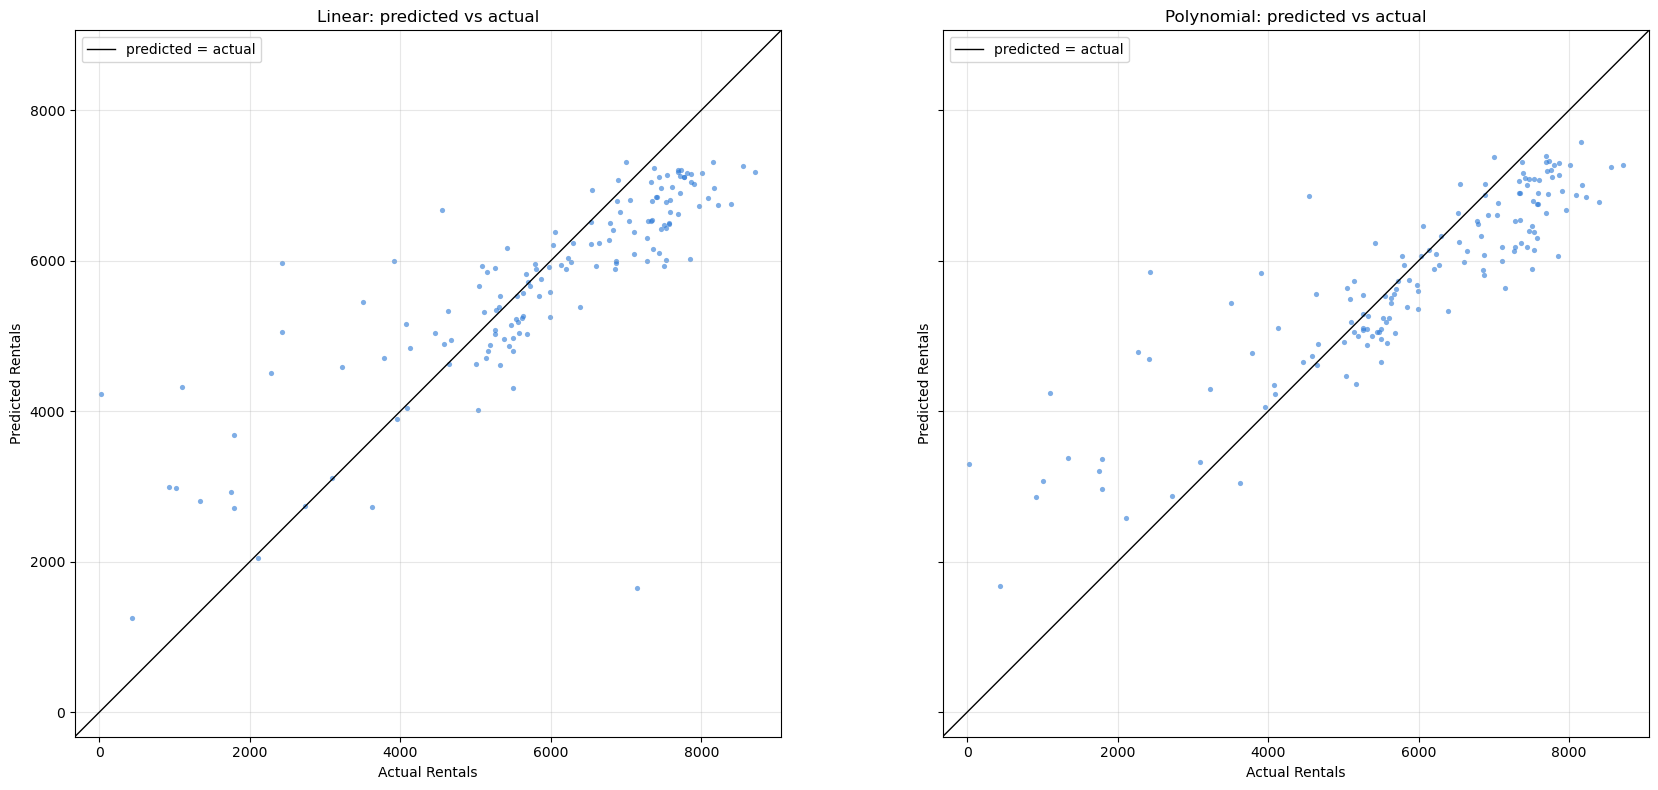

In [16]:
PLOTTING.predicted_vs_actual(actual=y_test, predictions=predictions);

## By Value

Rows, mean error and rmse in each band: first by actual value for both models, then by the value the final model predicted.

In [17]:
BAND_EDGES = [-np.inf, 2000, 4000, 6000, np.inf]
BAND_LABELS = ["below 2000", "2000 to 4000", "4000 to 6000", "6000 and above"]


def band(values, name):
	"""The Rentals band of each value (ex "2000 to 4000" holds 2000 and leaves out 4000), as a Series called name."""
	return pd.cut(values, BAND_EDGES, labels=BAND_LABELS, right=False).rename(name)


display(SCORING.error_by_group(y_test, predictions, by=band(y_test, "actual value")).round(3))
display(SCORING.error_by_group(y_test, predictions[[FINAL]], by=band(predictions[FINAL], f"value predicted by {FINAL}")).round(3))

rows mean error                 rmse           
                        Linear Polynomial    Linear Polynomial
actual value                                                  
below 2000        9   1971.425   1989.521  2233.897   2117.411
2000 to 4000     12   1142.683   1206.343  1733.398   1666.708
4000 to 6000     50    -30.192    -45.030   582.640    532.201
6000 and above   76   -762.069   -665.418  1052.278    833.718

,rows,mean error,rmse
,,Polynomial,Polynomial
value predicted by Polynomial,,,
below 2000,1,1231.983,1231.983
2000 to 4000,11,1253.808,1638.725
4000 to 6000,65,48.359,965.787
6000 and above,70,-551.552,836.561


## Results

- **The largest misses are days with few rentals, which both models predict far too high.** For the final model the 9 days below 2000 have an rmse of 2117.411 and the 12 days from 2000 to 4000 have 1666.708, against 532.201 on the 50 days from 4000 to 6000. All five of its largest misses are predictions that are too high, by 2306.804 to 3420.786, and four of them are days with 22 to 2425 rentals.
- **The pull toward the middle is partly a level the final model gets wrong.** By predicted value its mean error is 1253.808 on the 11 days it predicts from 2000 to 4000 and -551.552 on the 70 days it predicts at 6000 and above, against 48.359 on the 65 days in between.
- **Month 10 is the worst month for both models (1251.175 and 1350.177), and the error changes sign through the test period.** The final model is too low on average in months 8 to 10 (-246.535, -636.731 and -342.717) and too high in months 11 and 12 (160.766 and 342.745). Its lead over the linear model is widest in month 8 (779.162 against 1329.330), and in month 12 it is behind (925.881 against 894.801).
- **Added afterwards: one day explains the linear model's miss on the first 46 test days.** On 2012-08-17 `Temp` is 0.723 and `FeelsLike` is 0.242, a gap of 0.481, where the training days stay between -0.042 and 0.087. The linear model predicts 1655.827 for a day with 7148 rentals, and the polynomial model 5643.502. Without that day the linear model's first 46 days score 805.420, inside its fold range (704.347 to 891.022), and over all the days left the two models score 1020.113 and 973.663.